# Step 1. 데이터 뜯어보기 — API 명세서 믿지 말고 DB 직접 까보기

- **예상 소요 시간:** 약 40분 (코드 실행 + 자습 미션 포함)
- **목표:** 머신러닝 코드 한 줄도 안 짜고, 데이터만 까봐서 **실무 버그 3개의 복선**을 먼저 찾아낸다.

---

### 오늘의 상황
당신은 공공자전거(따릉이) 운영팀 백엔드 개발자다. 기획팀에서 요청이 왔다.

> **"내일 오전 8시에 자전거가 몇 대나 빌려갈지 예측하는 API 하나 만들어 주세요."**

Spring 개발자라면 이 요청을 받고 제일 먼저 뭘 할까?  
Controller부터 만들지 않는다. **DB 접속해서 테이블 스키마랑 실제 데이터 10줄(`SELECT * LIMIT 10`)부터 까본다.**  
머신러닝에서 이 작업을 **EDA(Exploratory Data Analysis, 탐색적 데이터 분석)**라고 부를 뿐이다.

### 이 노트북 공부법 (중요)
코드 셀 위에 **`[실행 전 예측]`** 질문이 붙어 있다.  
바로 실행하지 말고 **딱 10초만 머리로 먼저 찍어본 뒤** 실행하자. 내 예상과 실제 데이터가 다를 때 머리에 제일 오래 남고, 나중에 발표할 때도 할 말이 생긴다.

---
## 1. 데이터 받기 & 테이블 구조 확인 (`SELECT * LIMIT 5`)

UCI 공식 저장소에서 자전거 대여 데이터(`hour.csv`)를 바로 내려받아 열어본다.  
*(별도로 파일을 올릴 필요 없이 아래 셀을 실행하면 Colab이 자동으로 다운로드한다.)*

In [4]:
import os
import urllib.request
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

# 1) UCI 공식 저장소에서 zip 다운로드 (이미 있으면 건너뜀)
url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
os.makedirs("dataset", exist_ok=True)
zip_path = "dataset/bike_sharing_dataset.zip"

if not os.path.exists("dataset/hour.csv"):
    print("데이터 다운로드 중...")
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall("dataset")
    print("다운로드 및 압축 해제 완료!")

# 2) 시간 단위 데이터 로드
df = pd.read_csv("dataset/hour.csv")
print(f"전체 행(row) 수: {df.shape[0]:,}개, 컬럼(column) 수: {df.shape[1]}개")
df.head()

전체 행(row) 수: 17,379개, 컬럼(column) 수: 17개


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### 🔍 코드 뜯어보기
- **`import pandas as pd` / `import matplotlib.pyplot as plt`:**  
  데이터 분석 코드의 관례적 별칭(alias)이다. `pandas`는 **파이썬용 인메모리 DB 테이블(엑셀)** 도구, `matplotlib.pyplot`은 **그래프 그리는 도구**라고 생각하면 된다.
- **`urllib.request.urlretrieve(url, zip_path)`:**  
  외부 URL 파일을 내 디스크(Colab 임시 서버)로 바로 저장한다. 터미널의 `curl -o`와 같다.
- **`with zipfile.ZipFile(zip_path, "r") as zf:`:**  
  Java의 `try-with-resources` 문법과 똑같다. `with` 블록이 끝나면 파일 핸들을 자동으로 닫아준다(`close()`). `zf.extractall(".")`는 현재 폴더(`.`)에 압축을 전부 푼다.
- **`df = pd.read_csv("hour.csv")`:**  
  CSV 파일을 읽어 **DataFrame(`df`)** 객체로 만든다. Java로 치면 `List<BikeRowDto>`를 표 형태로 메모리에 올린 것이다.
- **`df.shape`:**  
  `(행 개수, 컬럼 개수)` 튜플을 돌려준다. `df.shape[0]`은 행 개수, `df.shape[1]`은 컬럼 개수다. f-string 안의 `:,`는 천 단위 콤마(`17,379`) 포맷이다.
- **`df.head()`:**  
  상위 5개 행만 출력한다. SQL의 `SELECT * FROM hour LIMIT 5;`와 같다. Colab에서는 셀 마지막 줄에 변수나 표현식을 두면 `print()` 없이도 예쁜 표로 렌더링된다.

### 컬럼 스키마 한눈에 보기 (DB 테이블 명세서)

방금 나온 17개 컬럼을 백엔드 API 관점으로 분류하면 이렇게 나뉜다.

| 구분 | 컬럼명 | 설명 |
| :--- | :--- | :--- |
| **메타(ID/날짜)** | `instant`, `dteday` | 행 번호(PK), 날짜(`YYYY-MM-DD`) |
| **시간 정보** | `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday` | 계절(1~4), 연도(0=2011, 1=2012), 월, 시(0~23), 공휴일, 요일, 평일 여부 |
| **날씨 정보** | `weathersit`, `temp`, `atemp`, `hum`, `windspeed` | 날씨 상태(1=맑음~4=폭우), 기온·체감온도·습도·풍속 *(0~1로 정규화됨)* |
| **정답(Target)** | `cnt` | **우리가 맞춰야 할 값.** 해당 시간의 총 자전거 대여 수 |
| **수상한 컬럼** | `casual`, `registered` | 비회원 대여 수, 회원 대여 수 *(이 둘은 끝에서 다시 본다)* |

---
### 체크포인트: NULL이 있나? 빠진 시간은 없나?

잠깐 암산해 보자.  
2011년(365일) + 2012년(윤년 366일) = **731일**이다.  
하루 24시간이면 `731 × 24 = 17,544`행이어야 정상인데, 아까 위에서 나온 행 수는 **`17,379`개**다. **165시간이 어디로 사라졌을까?**  
운영 DB 장애 조사하듯 바로 확인해 보자.

In [5]:
# 1) NULL(결측치) 확인
null_total = df.isnull().sum().sum()
print(f"전체 NULL 개수: {null_total}개")

# 2) 기간 및 빠진 시간 계산
n_days = df["dteday"].nunique()
expected_rows = n_days * 24
missing_hours = expected_rows - len(df)
print(f"기간: {df['dteday'].min()} ~ {df['dteday'].max()} (총 {n_days}일)")
print(f"정상이라면 {expected_rows:,}행이어야 함 → 실제 {len(df):,}행 ({missing_hours}시간 누락)")

# 3) 24시간이 다 안 찍힌 날 TOP 5 확인
print("\n[기록이 가장 많이 빠진 날짜 TOP 5]")
print(df.groupby("dteday").size().sort_values().head(5))

전체 NULL 개수: 0개
기간: 2011-01-01 ~ 2012-12-31 (총 731일)
정상이라면 17,544행이어야 함 → 실제 17,379행 (165시간 누락)

[기록이 가장 많이 빠진 날짜 TOP 5]
dteday
2012-10-29     1
2011-01-27     8
2012-10-30    11
2011-01-18    12
2011-01-26    16
dtype: int64


### 🔍 코드 뜯어보기
- **`df.isnull().sum().sum()` — 왜 `.sum()`을 두 번 부를까?**  
  1. `df.isnull()`: 테이블의 모든 칸을 `True`(NULL임) / `False`(값 있음)로 바꾼다. (파이썬에서 `True=1`, `False=0`)
  2. 첫 번째 `.sum()`: **컬럼별** NULL 개수를 합산한다. (결과: 17개 컬럼 목록)
  3. 두 번째 `.sum()`: 그 17개 숫자를 전부 더해 **테이블 전체** NULL 총합 숫자 1개를 뽑는다.
- **`df["dteday"].nunique()`:**  
  `n`umber of `unique` values. SQL의 `SELECT COUNT(DISTINCT dteday) FROM hour;`와 100% 같다.
- **`df.groupby("dteday").size().sort_values().head(5)`:**  
  메서드 체이닝이 길어 보이지만 SQL 한 줄로 번역하면 바로 이해된다.
  ```sql
  SELECT dteday, COUNT(*) AS cnt
  FROM hour
  GROUP BY dteday
  ORDER BY cnt ASC
  LIMIT 5;
  ```
  - `groupby("dteday")` = `GROUP BY dteday`
  - `.size()` = 그룹별 행 개수(`COUNT(*)`)
  - `.sort_values()` = 기본 오름차순 정렬(`ORDER BY ... ASC`). 내림차순은 `ascending=False`를 넘긴다.
  - `.head(5)` = `LIMIT 5`

`2012-10-29`를 보자. 하루에 겨우 **1시간**만 찍혀 있다.  
실제로 저 날 워싱턴 D.C.에 **허리케인 샌디(Hurricane Sandy)**가 상륙해서 자전거 운영이 멈췄다.  
NULL이 0개라고 해서 데이터가 완벽한 게 아니다. **"행 자체가 빠져 있는 경우"**는 `isnull()`로 안 잡힌다. 실무 배치 로그 검증할 때랑 똑같다.

---
## 2. 상식 검증 — 탐정처럼 질문 4개 던지기

다른 사람들이 데이터 분석을 잘해 보이는 이유는 어려운 통계 함수를 써서가 아니다.  
**"내 상식이 맞나?" 질문 던지고 코드로 확인하는 순서**를 밟기 때문이다.

### 질문 1. 공식 문서가 진짜 맞을까?
> **[실행 전 예측]**  
> UCI 공식 Readme 문서에는 `season` 컬럼이 `1=봄, 2=여름, 3=가을, 4=겨울`이라고 적혀 있다.  
> 진짜 `season=1`에 3~5월 데이터가 들어 있을까?

In [5]:
# season별 포함된 월(mnth)과 평균 기온(temp) 확인
season_check = df.groupby("season").agg(
    months=("mnth", lambda x: sorted(int(v) for v in x.unique())),
    avg_temp=("temp", "mean"),
    avg_cnt=("cnt", "mean")
)
print(season_check)

                 months  avg_temp     avg_cnt
season                                       
1         [1, 2, 3, 12]  0.299147  111.114569
2          [3, 4, 5, 6]  0.544663  208.344069
3          [6, 7, 8, 9]  0.706410  236.016237
4       [9, 10, 11, 12]  0.423138  198.868856


### 🔍 코드 뜯어보기
여기서 파이썬 초보가 제일 당황하는 문법 2개가 한 번에 나온다. 하나씩 쪼개보자.

1. **`.agg(새컬럼명=("대상컬럼", "집계함수"))`**  
   SQL의 `SELECT` 절에 여러 집계 함수를 한 번에 적는 문법이다.
   ```sql
   SELECT season,
          AVG(temp) AS avg_temp,
          AVG(cnt)  AS avg_cnt
   FROM hour
   GROUP BY season;
   ```
2. **`lambda x: sorted(int(v) for v in x.unique())`**  
   - `lambda x: ...`는 Java의 람다식 `x -> ...`와 완전히 같다. 여기서 `x`는 각 계절 그룹에 속한 `mnth` 컬럼 값들의 묶음이다.
   - `x.unique()`: 중복을 제거한 월 목록을 뽑는다. (예: `[1, 2, 3, 12]`)
   - `sorted(int(v) for v in ...)`: 뽑힌 값들을 파이썬 기본 정수(`int`)로 바꾸고 오름차순 정렬한다. *(NumPy 2.x 환경에서 `np.int64(1)`처럼 지저분하게 찍히는 걸 막으려고 `int(v)`로 감쌌다.)*

### 질문 1 결과: 문서 버그 발견!
- `season=1`을 보자. **12월, 1월, 2월, 3월**이 들어 있고 평균 기온(`avg_temp`)도 제일 낮다. **겨울**이다.
- 워싱턴 D.C. 기준 동지~춘분 구간을 `1`로 묶었는데, 문서 작성자가 `1=봄`으로 잘못 적은 유명한 오류다.
- **교훈:** 백엔드에서 외부 API 명세서만 믿고 개발하다가 실제 DB 조회해보고 뒤집어지는 거랑 똑같다. 데이터는 무조건 까봐야 한다.

---
### 질문 2. 평일과 주말, 몇 시에 자전거를 제일 많이 탈까?
> **[실행 전 예측]**  
> 그래프를 그리기 전에 머리로 모양을 5초만 그려보자.  
> - 평일(`workingday=1`)은 몇 시에 봉우리가 솟을까?  
> - 주말/공휴일(`workingday=0`)은 몇 시에 봉우리가 솟을까?

*(Colab 기본 환경에서 한글 폰트가 `□□□`로 깨지는 걸 막기 위해 그래프 라벨만 영어로 적는다.)*

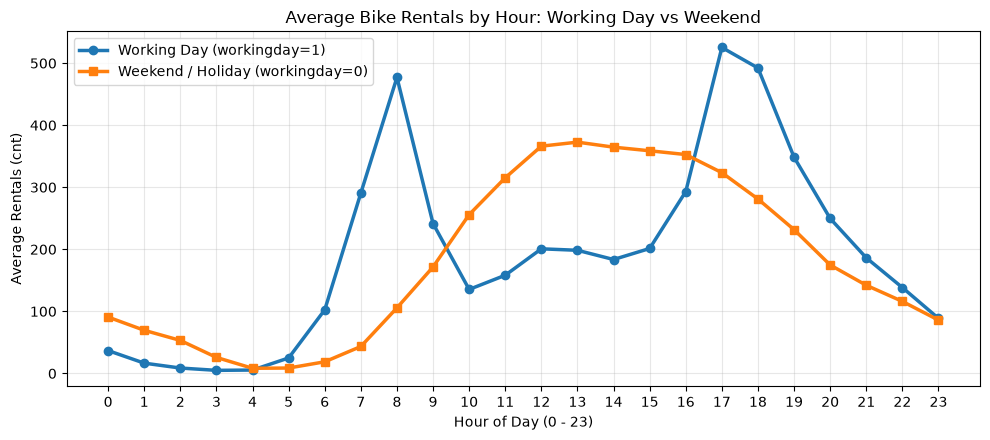

평일 피크 시간 TOP 3:
hr
17    525.3
18    492.2
8     477.0
Name: 1, dtype: float64

주말/공휴일 피크 시간 TOP 3:
hr
13    372.7
12    366.3
14    364.6
Name: 0, dtype: float64


In [6]:
# 평일(workingday=1) vs 주말·공휴일(workingday=0) 시간대별 평균 대여량
hourly = df.groupby(["workingday", "hr"])["cnt"].mean().unstack(level=0)

plt.figure(figsize=(10, 4.5))
plt.plot(hourly.index, hourly[1], marker="o", linewidth=2.5, label="Working Day (workingday=1)")
plt.plot(hourly.index, hourly[0], marker="s", linewidth=2.5, label="Weekend / Holiday (workingday=0)")
plt.title("Average Bike Rentals by Hour: Working Day vs Weekend")
plt.xlabel("Hour of Day (0 - 23)")
plt.ylabel("Average Rentals (cnt)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("평일 피크 시간 TOP 3:")
print(hourly[1].sort_values(ascending=False).head(3).round(1))
print("\n주말/공휴일 피크 시간 TOP 3:")
print(hourly[0].sort_values(ascending=False).head(3).round(1))

### 🔍 코드 뜯어보기
- **`df.groupby(["workingday", "hr"])["cnt"].mean().unstack(level=0)`**  
  한 줄에 핵심 변환이 3단계로 들어있다.
  1. `groupby(["workingday", "hr"])`: `(평일여부, 시간)` 조합별로 묶는다. (총 2 × 24 = 48개 그룹)
  2. `["cnt"].mean()`: 각 그룹의 `cnt` 평균을 계산한다. 여기까지는 세로로 48줄짜리 표다.
  3. **`.unstack(level=0)`**: 엑셀의 **피벗 테이블(Pivot)**이다. 0번째 그룹 기준(`workingday`: 0과 1)을 가로 컬럼으로 펼쳐서, **행=시간(0~23), 열=주말(0)/평일(1)** 24×2 표로 바꾼다. 그래야 `hourly[1]`(평일 선)과 `hourly[0]`(주말 선)을 바로 그릴 수 있다.
- **`plt.figure(figsize=(10, 4.5))`:** 그래프 도화지 크기를 가로 10인치, 세로 4.5인치로 연다.
- **`plt.plot(x값, y값, marker=..., label=...)`:**  
  - `hourly.index`는 시간(0~23), `hourly[1]`은 평일 평균 대여량이다.
  - `marker="o"`(동그라미), `marker="s"`(네모)는 데이터 포인트 점 모양이고, `label=...`은 우측 상단 범례(`plt.legend()`)에 표시될 이름이다.
- **`plt.xticks(range(0, 24))`:** X축 눈금을 0시부터 23시까지 1시간 단위로 전부 표시한다. *(안 넣으면 0, 5, 10, 15, 20처럼 듬성듬성 찍혀서 8시·17시 피크가 한눈에 안 보인다.)*
- **`.round(1)`:** 소수점 첫째 자리까지 반올림해서 보기 좋게 출력한다.

### 질문 2 결과 & 발표 꿀팁
- **평일:** 오전 8시(출근), 오후 5~6시(퇴근)에 뾰족한 **쌍봉**이 솟는다.
- **주말:** 낮 12시~오후 4시에 완만한 **산 하나**가 생긴다.
- **Step 4 복선:** 시간(`hr`)이 커진다고 대여량이 일직선으로 늘어나지 않는다. 뒤에서 **선형회귀(직선 긋기) 모델이 왜 망하는지** 설명할 때 바로 이 그래프를 다시 꺼낸다.
- **30분 발표 팁:** 발표 때 EDA 설명은 이 그래프 1장만 띄워도 충분하다. 청중이 5초 만에 "출퇴근이랑 주말 패턴이 완전히 다르네" 하고 이해한다.

---
### 질문 3. 비·눈이 올수록(`weathersit`) 대여량이 줄어들까?
> **[실행 전 예측]**  
> `1(맑음) → 2(흐림) → 3(비/눈) → 4(폭우/폭설)` 순서로 평균 대여량이 쭉 떨어질 것이다.  
> 그런데 `weathersit=4`(폭우/폭설) 데이터는 전체 17,379건 중에 몇 건이나 있을까?

In [7]:
weather_stats = df.groupby("weathersit")["cnt"].agg(["count", "mean", "min", "max"])
weather_stats["ratio(%)"] = (weather_stats["count"] / len(df) * 100).round(2)
print(weather_stats)

            count        mean  min  max  ratio(%)
weathersit                                       
1           11413  204.869272    1  977     65.67
2            4544  175.165493    1  957     26.15
3            1419  111.579281    1  891      8.17
4               3   74.333333   23  164      0.02


### 🔍 코드 뜯어보기
- **`df.groupby("weathersit")["cnt"].agg(["count", "mean", "min", "max"])`:**  
  한 컬럼(`cnt`)에 여러 집계 함수를 리스트로 한꺼번에 적용한다. SQL의 `SELECT COUNT(cnt), AVG(cnt), MIN(cnt), MAX(cnt) FROM hour GROUP BY weathersit;`와 같다.
- **`weather_stats["ratio(%)"] = weather_stats["count"] / len(df) * 100`:**  
  Java처럼 `for`문을 돌며 행마다 나누지 않는다! `pandas`에서는 컬럼 전체에 `/ len(df) * 100`을 쓰면 **모든 행에 한 번에 계산(벡터 연산)**되고, 왼쪽처럼 새 컬럼명을 지정하면 표 오른쪽 끝에 새 컬럼이 바로 붙는다.

### 질문 3 결과: 평균에 속지 말고 건수(`count`)를 같이 봐라
- `weathersit=4`(폭우/폭설) 평균이 약 74대로 나온다. 생각보다 많이 타네? 싶지만 옆의 **`count`**를 보자.
- 전체 17,379건 중 고작 **3건(0.02%)**뿐이다. 샘플이 3건뿐인 조건에서는 모델이 규칙을 배울 수 없다.
- **습관 들이기:** 그룹별 평균을 뽑을 때는 항상 **`count`를 세트로 같이 찍는다.**

---
### 질문 4. 2011년과 2012년은 대여량이 비슷할까?
> **[실행 전 예측]**  
> 같은 도시의 공공자전거 서비스다. 2011년(`yr=0`)과 2012년(`yr=1`) 평균 대여량은 비슷할까?

    count        mean
yr                   
0    8645  143.794448
1    8734  234.666361

2011년 대비 2012년 평균 대여량 증가율: +63.2%


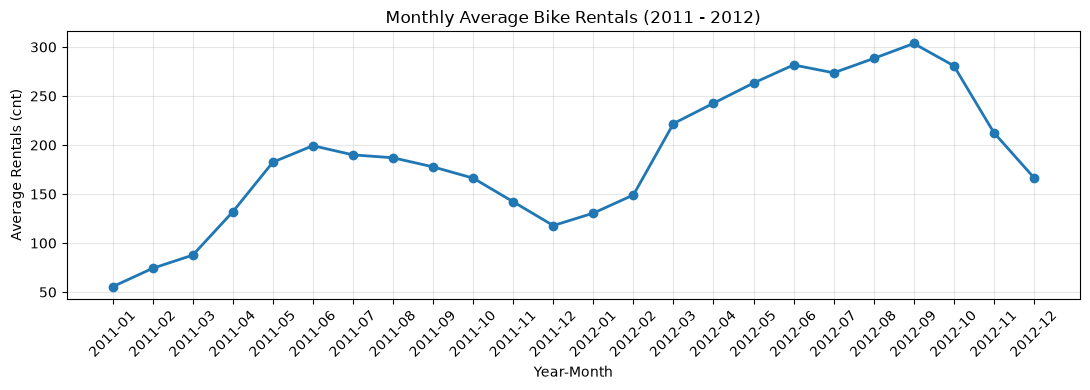

In [7]:
# 1) 연도별 평균 비교
yr_stats = df.groupby("yr")["cnt"].agg(["count", "mean"])
growth = (yr_stats.loc[1, "mean"] / yr_stats.loc[0, "mean"] - 1) * 100
print(yr_stats)
print(f"\n2011년 대비 2012년 평균 대여량 증가율: +{growth:.1f}%")

# 2) 24개월 시계열 추이 그래프
df["ym"] = df["dteday"].str.slice(0, 7)  # 'YYYY-MM'
monthly = df.groupby("ym")["cnt"].mean()

plt.figure(figsize=(11, 4))
plt.plot(monthly.index, monthly.values, marker="o", linewidth=2)
plt.title("Monthly Average Bike Rentals (2011 - 2012)")
plt.xlabel("Year-Month")
plt.ylabel("Average Rentals (cnt)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 🔍 코드 뜯어보기
- **`yr_stats.loc[1, "mean"]`:**  
  `.loc[행이름, 컬럼이름]`은 표에서 특정 셀 1개를 정확히 꺼내는 문법이다. 여기서는 `yr=1`(2012년) 행의 `mean` 컬럼 값을 꺼낸다. *(참고: 행 번호 숫자로 꺼낼 때는 `.iloc[행번호, 열번호]`를 쓴다.)*
- **`df["dteday"].str.slice(0, 7)`:**  
  `dteday` 컬럼의 문자열(`'2011-01-01'`) 전체에 대해 Java의 `substring(0, 7)`을 한 번에 적용해 `'2011-01'`(연-월)만 잘라낸다. `pandas`에서 문자열 함수를 컬럼 전체에 쓸 때는 `.str.`을 꼭 붙여야 한다.
- **`monthly.index` vs `monthly.values`:**  
  `groupby` 결과가 1개 컬럼(Series)일 때, `.index`는 그룹 키(`'2011-01'`, `'2011-02'`, ...), `.values`는 계산된 숫자 배열이다. Java의 `Map.keySet()`과 `Map.values()` 관계라고 보면 딱 맞다.
- **`plt.xticks(rotation=45)`:** X축의 `'2011-01'` 글자들이 겹치지 않도록 45도 기울인다.

### 질문 4 결과: 서비스가 1년 만에 60% 넘게 성장했다
- 2011년 평균 약 144대 → 2012년 평균 약 235대 (**+63% 성장**).
- 계절 파도(여름 높고 겨울 낮음)를 타면서 전체 레벨 자체가 우상향하고 있다.
- **Step 3 복선:** 이렇게 시간이 지날수록 값이 커지는 데이터에서, 2011년과 2012년을 랜덤으로 섞어 학습하고 테스트하면 어떻게 될까? 2012년 8월 15일 10시와 12시 데이터를 보고 11시를 맞추는 **컨닝 테스트**가 된다. Step 3에서 이 버그를 직접 터뜨려 본다.

---
## 3. 오늘의 마지막 발견 — 수상한 컬럼 2개 (`casual`, `registered`)

아까 맨 처음 `df.head()`를 찍었을 때 오른쪽 끝에 `casual`, `registered`, `cnt`가 나란히 있었다.  
두 컬럼을 더해보면 어떻게 될까?

In [8]:
is_exact_sum = bool((df["casual"] + df["registered"] == df["cnt"]).all())
print(f"모든 행에서 casual + registered == cnt 인가? → {is_exact_sum}")
df[["dteday", "hr", "casual", "registered", "cnt"]].head(5)

모든 행에서 casual + registered == cnt 인가? → True


,dteday,hr,casual,registered,cnt
0,2011-01-01,0,3,13,16
1,2011-01-01,1,8,32,40
2,2011-01-01,2,5,27,32
3,2011-01-01,3,3,10,13
4,2011-01-01,4,0,1,1


### 🔍 코드 뜯어보기
- **`(df["casual"] + df["registered"] == df["cnt"]).all()`:**  
  1. `df["casual"] + df["registered"] == df["cnt"]`: 17,379개 행 각각에 대해 더한 값이 `cnt`와 같은지 비교해 `[True, True, ...]` 불리언 목록을 만든다.
  2. `.all()`: 그 17,379개가 **전부 `True`**일 때만 `True`를 반환한다. Java Stream의 `.allMatch(...)`와 똑같다.
- **`df[["dteday", "hr", "casual", "registered", "cnt"]]` — 왜 대괄호가 `[[...]]` 두 겹일까?**  
  파이썬 초보가 제일 자주 헷갈리는 포인트다.
  - `df["cnt"]` (대괄호 1개): 컬럼 **1개**만 뽑는다 (1차원 Series).
  - `df[["dteday", "cnt"]]` (대괄호 2개): 컬럼 이름 **리스트(`[...]`)**를 넘겨서 원하는 컬럼 **여러 개**만 추린 새 표(2차원 DataFrame)를 뽑는다. SQL의 `SELECT dteday, hr, casual, registered, cnt FROM hour LIMIT 5;`와 같다.

모든 17,379행에서 예외 없이 **`casual + registered = cnt`**다.

### 백엔드 API 설계 관점에서 잠깐 멈춰 생각해보자
우리가 만들 API의 스펙은 이렇다.
```http
POST /api/v1/predict-rentals
{
  "date": "2026-11-24",
  "hour": 8,
  "temp": 0.45,
  "weathersit": 1
}
```
이 요청 JSON에 **`casual`(내일 8시 비회원 대여량)**과 **`registered`(내일 8시 회원 대여량)**를 넣을 수 있을까?  
**당연히 못 넣는다.** 내일이 아직 안 왔는데 내일 몇 명이 빌릴지 어떻게 아는가.

그런데 입문자가 데이터 테이블을 안 뜯어보고 "일단 컬럼 다 넣고 모델 돌려보자!" 하면 어떻게 될까?  
**Step 2에서 일부러 이 두 컬럼을 넣고 돌려서 '점수 100점짜리 가짜 모델' 버그를 직접 눈으로 확인한다.**

---
## 4. 직접 해보는 자습 미션 (10분)

눈으로만 읽으면 남한테 설명할 때 입이 안 떨어진다. 아래 2개만 직접 코드 3~5줄로 쳐보자.

- **미션 1:** 기온(`temp`)이 올라갈수록 무조건 자전거를 많이 탈까? 아니면 너무 더우면 오히려 줄어들까?  
  *(힌트: `pd.cut(df["temp"], bins=5)`로 기온을 5구간으로 나눈 뒤 `groupby`로 `cnt` 평균 확인)*
- **미션 2:** 1년 중 대여량이 가장 많은 달(`mnth`)과 가장 적은 달은 언제일까?  
  *(힌트: `df.groupby("mnth")["cnt"].mean().sort_values()`)*

                count        mean
temp                             
(0.019, 0.216]   1070   65.069159
(0.216, 0.412]   5357  123.066828
(0.412, 0.608]   5117  194.671096
(0.608, 0.804]   5126  260.695279
(0.804, 1.0]      709  326.276446


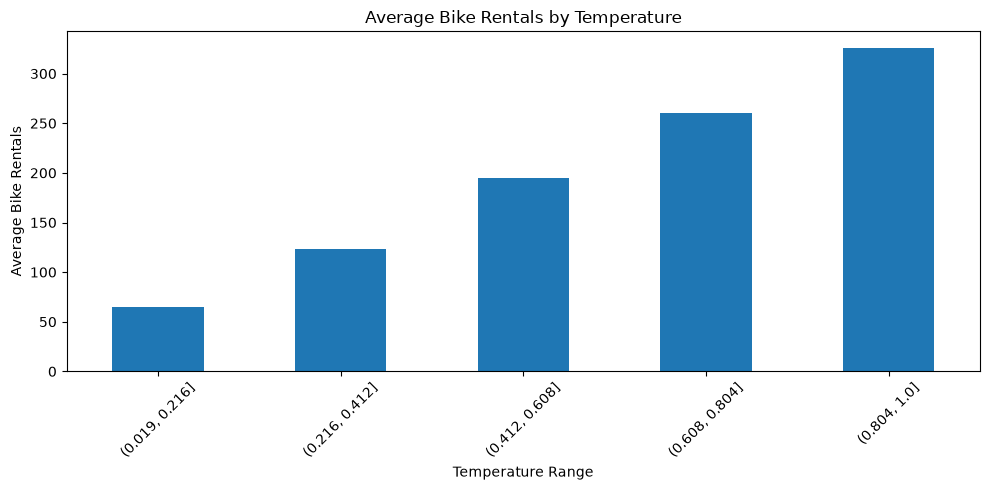

In [9]:
# [미션 1] 기온 구간별 평균 대여량 확인하기
# TODO: 아래에 코드를 작성해 보세요.
# 온도를 5개 구간으로 나누기
temp_bins = pd.cut(df["temp"], bins=5)
# 구간별 평균 대여량 계산
temp_summary = df.groupby(temp_bins, observed=False)["cnt"].agg(["count", "mean"])
print(temp_summary)
# 그래프 그리기
temp_summary["mean"].plot(kind="bar", figsize=(10, 5))

plt.title("Average Bike Rentals by Temperature")
plt.xlabel("Temperature Range")
plt.ylabel("Average Bike Rentals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

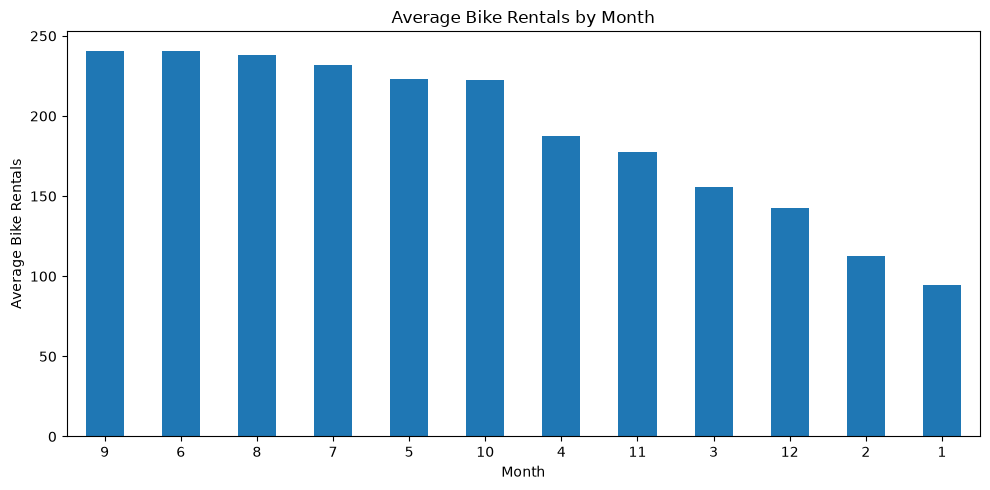

In [10]:
# [미션 2] 월별(mnth) 평균 대여량 확인하기
# TODO: 아래에 코드를 작성해 보세요.\

mnth_summary = df.groupby("mnth")["cnt"].mean().sort_values(ascending=False).round(1)

plt.figure(figsize=(10, 5))

mnth_summary.plot(kind="bar")

plt.title("Average Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Bike Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

<details>
<summary>정답 코드 보기 (먼저 직접 쳐본 뒤 열어보세요)</summary>

```python
# 미션 1 정답
temp_bins = pd.cut(df["temp"], bins=5)
print(df.groupby(temp_bins, observed=False)["cnt"].agg(["count", "mean"]))

# 미션 2 정답
print(df.groupby("mnth")["cnt"].mean().sort_values(ascending=False).round(1))
```

- **미션 1 해석:** 기온 구간이 올라갈수록 대여량이 늘어나지만, 가장 더운 구간(0.8~1.0)에서도 크게 꺾이지 않거나 살짝 둔화되는 패턴을 볼 수 있다. (단, 가장 더운 구간 `count`가 상대적으로 적은 것도 함께 체크!)
- **미션 2 해석:** 6~9월(여름~초가을)이 가장 많고, 1~2월(한겨울)이 가장 적다.
</details>

---
## 5. 30분 발표용 정리 (Step 1 분량 = 발표에서 약 4분)

방금 40분 동안 공부한 내용을 남에게 다 설명할 필요는 없다.  
발표에서는 **딱 2가지만** 꺼내서 보여주면 된다.

### ① 내가 직접 채워보는 3줄 요약
*(이 셀을 더블클릭해서 본인 말투로 한 줄씩 채워보세요)*
- 데이터 까보고 제일 의외였던 점: `(여기에 입력)`
- 평일/주말 그래프에서 잡은 핵심 패턴: `(여기에 입력)`
- 모델 돌리기 전에 미리 지워야 할 컬럼과 이유: `(여기에 입력)`

---
### ② 발표 대본 샘플 (그대로 읽어도 어색하지 않은 구어체, 약 2~3분)

> "저도 처음엔 바로 머신러닝 모델부터 돌려보려고 했는데요. 백엔드 개발할 때도 API 만들기 전에 DB 테이블부터 까보잖아요. 똑같이 데이터부터 열어봤더니 모델 돌리기 전에 벌써 3가지를 건졌습니다.
>
> 첫째, 공식 문서에는 `season=1`이 봄이라고 되어 있는데 실제 월을 찍어보니 12월~3월 겨울이었습니다. 외부 API 문서만 믿고 개발하다 장애 나는 거랑 똑같더라고요.
>
> 둘째, 이 그래프 한 장만 보시면 됩니다. *(평일 vs 주말 시간대 그래프 화면 공유)* 평일은 출근 8시, 퇴근 5시에 뾰족하게 솟고 주말은 낮 1~3시에 둥글게 올라옵니다. 시간 숫자만 보고 직선으로 예측하면 절대 못 맞추겠다는 감이 여기서 바로 왔습니다.
>
> 셋째, `casual`이랑 `registered` 컬럼을 더하니까 정확히 정답 `cnt`랑 똑같았습니다. 내일 대여량을 예측해야 하는데 내일 비회원 대여량을 입력으로 받을 순 없잖아요? 근데 이걸 안 지우고 모델에 넣으면 어떻게 되는지, 다음 단계에서 일부러 한번 버그를 터뜨려 봤습니다."

---
**Step 1 완료!**  
다음 **Step 2**에서는 바닥 모델(평균 찍기)로 기준 점수를 잡고, 방금 찾은 `casual`/`registered` 컬럼으로 **함정 1(데이터 누수)**을 직접 터뜨려 본다.